# EDDA

### Setup

In [1]:
import sys
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis.eda_helper import load_apparel_data


df = load_apparel_data()
print(df.head())
print(f"\nDataFrame Shape: {df.shape}")
print(f"Index Frequency: {df.index.freq}")


# Define primary forecasting target (Not Seasonally Adjusted)
y_nsa = df["apparel_sales_nsa"]

# Isolate Seasonally Adjusted series for comparison
df_sa = df[["apparel_sales_sa"]] if "apparel_sales_sa" in df.columns else None

print(f"Target Series: {y_nsa.name}")
print(f"Total Observations: {len(y_nsa)}")
if df_sa is not None and not df_sa.empty:
    print(f"Comparison SA Series found: {list(df_sa.columns)}")


                  apparel_sales_nsa  apparel_sales_sa    cpi  cpi_is_imputed  \
observation_date                                                               
1992-01-01                   6734.0            9459.0  138.3               0   
1992-02-01                   7302.0            9444.0  138.6               0   
1992-03-01                   8245.0            9325.0  139.1               0   
1992-04-01                   9152.0            9610.0  139.4               0   
1992-05-01                   9294.0            9477.0  139.7               0   

                  unrate  unrate_is_imputed  
observation_date                             
1992-01-01           7.3                  0  
1992-02-01           7.4                  0  
1992-03-01           7.4                  0  
1992-04-01           7.4                  0  
1992-05-01           7.6                  0  

DataFrame Shape: (415, 6)
Index Frequency: <MonthBegin>
Target Series: apparel_sales_nsa
Total Observations: 415
Com

### Part A: Annual Totals and Calendar Seasonality
Analyzing historical retail clothing sales requires examining structural shifts at the annual level and identifying repetitive patterns within the calendar year. Because our dataset is Not Seasonally Adjusted (NSA), the monthly data contains massive spikes that dictate annual inventory and staffing strategies.

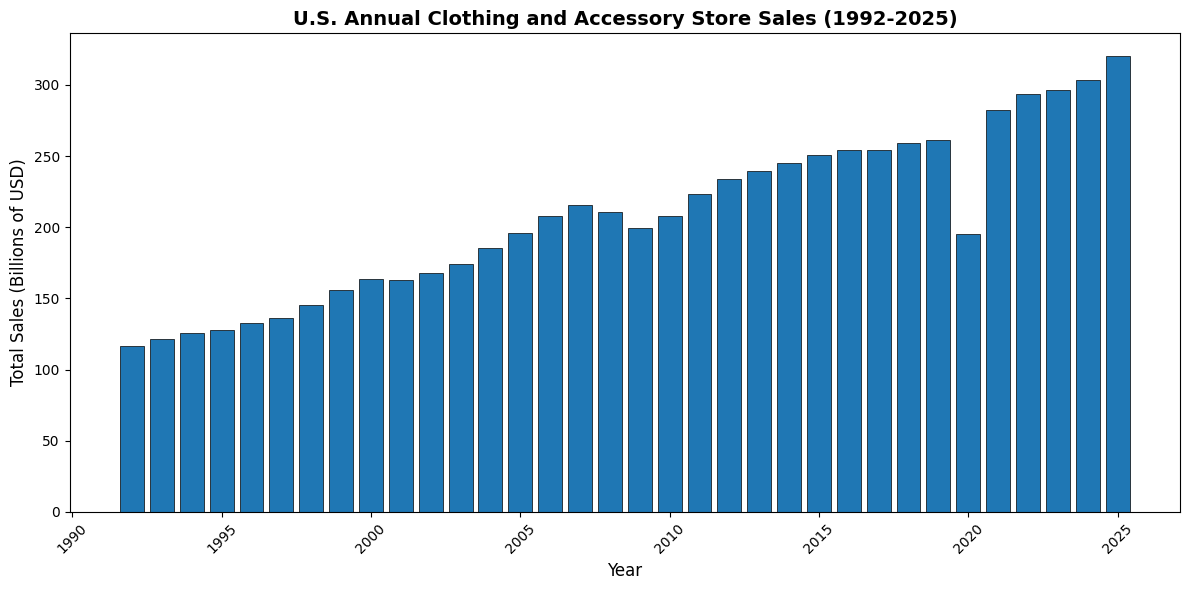

Trailing 12-Month (TTM) Total Sales: $329,916.00 million


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter for complete years only (1992 to 2025)
df_complete = df.loc["1992-01-01":"2025-12-01"].copy()

# 2. Resample and sum to annual totals (in billions for readability)
annual_sales = df_complete["apparel_sales_nsa"].resample("YE").sum() / 1000

# 3. Plot annual totals bar chart
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(annual_sales.index.year, annual_sales.values, color="#1f77b4", edgecolor="black", linewidth=0.5)
ax.set_title("U.S. Annual Clothing and Accessory Store Sales (1992-2025)", fontsize=14, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Sales (Billions of USD)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Calculate Trailing 12-Month (TTM) total using the latest available data in the full dataset
ttm_sales = df["apparel_sales_nsa"].iloc[-12:].sum()
print(f"Trailing 12-Month (TTM) Total Sales: ${ttm_sales:,.2f} million")

### Monthly Share of Annual Sales

To understand intra-year seasonality, we calculate each month's percentage contribution to its respective calendar year total. Averaging these proportions across multiple years highlights structural consumer behavior.

Pandemic Handling: The years 2020 and 2021 experienced unprecedented retail distortions due to lockdowns and fiscal stimulus. To maintain a clean baseline representative of typical consumer behavior, we exclude 2020 and 2021, selecting the last 10 non-pandemic complete years (2014 through 2025, omitting 2020 and 2021

In [ ]:
# Use the 10 most recent complete non-COVID years (2025 included).
excluded_years = {2020, 2021}
all_complete_years = [year for year in range(1992, 2026) if year not in excluded_years]
recent_10_years = all_complete_years[-10:]
print(f"Selected years for monthly-share analysis: {recent_10_years}")
print("COVID years excluded: 2020, 2021")

df_recent = df[df.index.year.isin(recent_10_years)].copy()
df_recent["year"] = df_recent.index.year
df_recent["month"] = df_recent.index.month

annual_totals = df_recent.groupby("year")["apparel_sales_nsa"].transform("sum")
df_recent["monthly_share"] = df_recent["apparel_sales_nsa"] / annual_totals
avg_monthly_share = df_recent.groupby("month")["monthly_share"].mean() * 100
print("\nAverage monthly share of annual sales (%):")
print(avg_monthly_share.round(2))

nov_dec_share = avg_monthly_share.loc[[11, 12]].sum()
print(f"\nCombined November–December share: {nov_dec_share:.2f}%")
print(f"December share alone: {avg_monthly_share.loc[12]:.2f}%")

Selected years for monthly-share analysis: [2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]
COVID years excluded: 2020, 2021

Average monthly share of annual sales (%):
month
1      6.04
2      6.85
3      8.11
4      7.93
5      8.60
6      7.85
7      8.07
8      8.70
9      7.49
10     7.98
11     9.33
12    13.05
Name: monthly_share, dtype: float64

Combined November–December share: 22.38%
December share alone: 13.05%


### December Peak and January Trough Levels

In [ ]:
# Summarize seasonal changes rather than treating long-run nominal maxima/minima as seasonality.
sales = df["apparel_sales_nsa"]
dec_sales = sales[sales.index.month == 12]
jan_sales = sales[sales.index.month == 1]
print("December levels (billions of nominal USD):")
for date in ["1992-12-01", "1999-12-01", "2025-12-01"]:
    print(f"{date[:4]}: ${sales.loc[date] / 1000:,.1f}B")

dec_jan = pd.DataFrame({"dec": dec_sales})
dec_jan["jan_next"] = [
    sales.get(pd.Timestamp(year=d.year + 1, month=1, day=1), float("nan"))
    for d in dec_jan.index
]
dec_jan = dec_jan.dropna()
dec_jan["drop_pct"] = (dec_jan["jan_next"] / dec_jan["dec"] - 1) * 100
print(f"\nAverage Dec-to-following-Jan change: {dec_jan['drop_pct'].mean():.1f}%")
print(f"Range: {dec_jan['drop_pct'].min():.1f}% to {dec_jan['drop_pct'].max():.1f}%")
for year in [1992, 1999, 2025]:
    dec = sales.loc[f"{year}-12-01"]
    jan_nov_mean = sales.loc[f"{year}-01-01":f"{year}-11-01"].mean()
    print(f"December excess over Jan–Nov monthly average, {year}: ${(dec - jan_nov_mean) / 1000:,.1f}B")
recent = sales.loc["2016-01-01":"2019-12-01"]
print("\nRecent pre-COVID seasonal level (2016–2019):")
print(f"Mean December: ${recent[recent.index.month == 12].mean()/1000:,.1f}B")
print(f"Mean January: ${sales.loc['2017-01-01':'2020-01-01'][lambda s: s.index.month == 1].mean()/1000:,.1f}B")

December levels (billions of nominal USD):
1992: $17.8B
1999: $23.6B
2025: $41.9B

Average Dec-to-following-Jan change: -55.2%
Range: -62.3% to -49.8%
December excess over Jan–Nov monthly average, 1992: $8.8B
December excess over Jan–Nov monthly average, 1999: $11.6B
December excess over Jan–Nov monthly average, 2025: $16.6B

Recent pre-COVID seasonal level (2016–2019):
Mean December: $33.5B
Mean January: $15.7B


# Part B: Trend, Seasonality, and Regimes
Analyzing the temporal structure of retail dataset helps uncover long-term macroeconomic trends, repeating calendar cycles, and structural shifts in consumer spending habits.

### B1. NSA vs. SA Series Overlay & Conceptual Difference

Seasonally Adjusted (SA) series remove predictable calendar variations—such as the massive pre-holiday retail surge in December and the post-holiday drop in January—using smoothing algorithms like X-13ARIMA-SEATS.

For an operational decision like inventory stocking and temporary staffing, relying on a seasonally adjusted target is incorrect. A manager cannot stock shelves with "smoothed" average inventory; they need to prepare for the physical, unadjusted volume of merchandise that walks out the door during the December holiday peak.

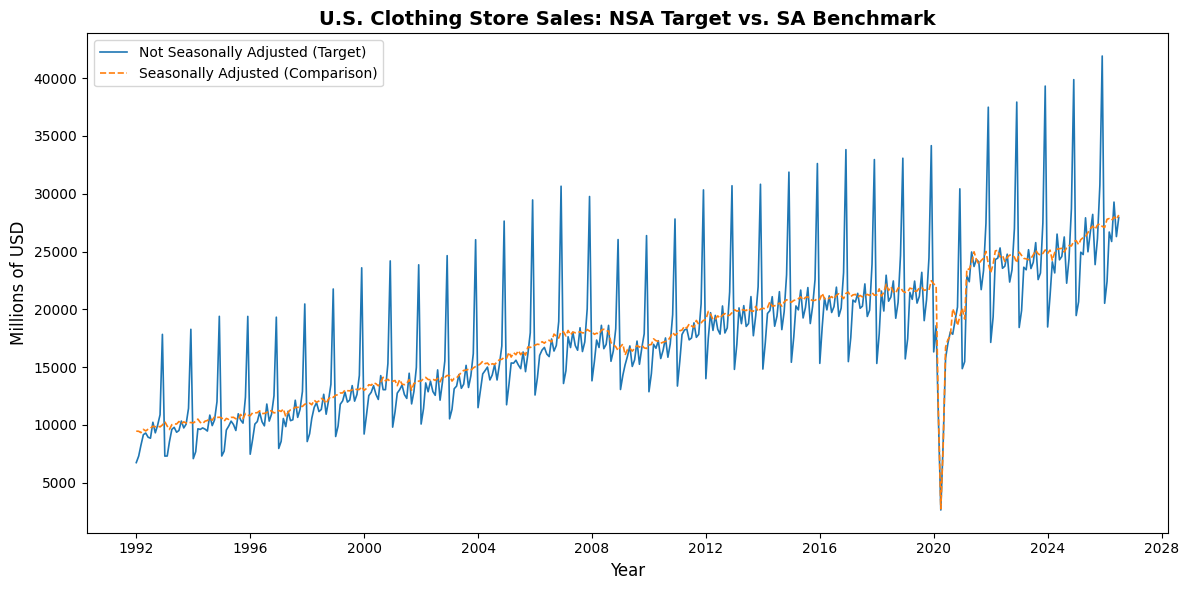

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

fig, ax = plt.subplots(figsize=(12, 6))

# Plot Not Seasonally Adjusted (Target)
ax.plot(df.index, df["apparel_sales_nsa"], label="Not Seasonally Adjusted (Target)", color="#1f77b4", linewidth=1.2)

# Plot Seasonally Adjusted (Comparison)
if "apparel_sales_sa" in df.columns:
    ax.plot(df.index, df["apparel_sales_sa"], label="Seasonally Adjusted (Comparison)", color="#ff7f0e", linestyle="--", linewidth=1.2)

ax.set_title("U.S. Clothing Store Sales: NSA Target vs. SA Benchmark", fontsize=14, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Millions of USD", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### What I see
The NSA series contains a strong recurring December peak and January decline, while the seasonally adjusted series is smoother. This supports using NSA sales as the operational target while using SA as a trend/context benchmark.

### Seasonal Plot (Monthly Profiles by Year)

A seasonal plot stacks each calendar year on top of one another across the 12 months (January to December). This visualization immediately reveals whether the seasonal shape remains consistent over time or if the magnitude of the holiday spike shifts across decades.

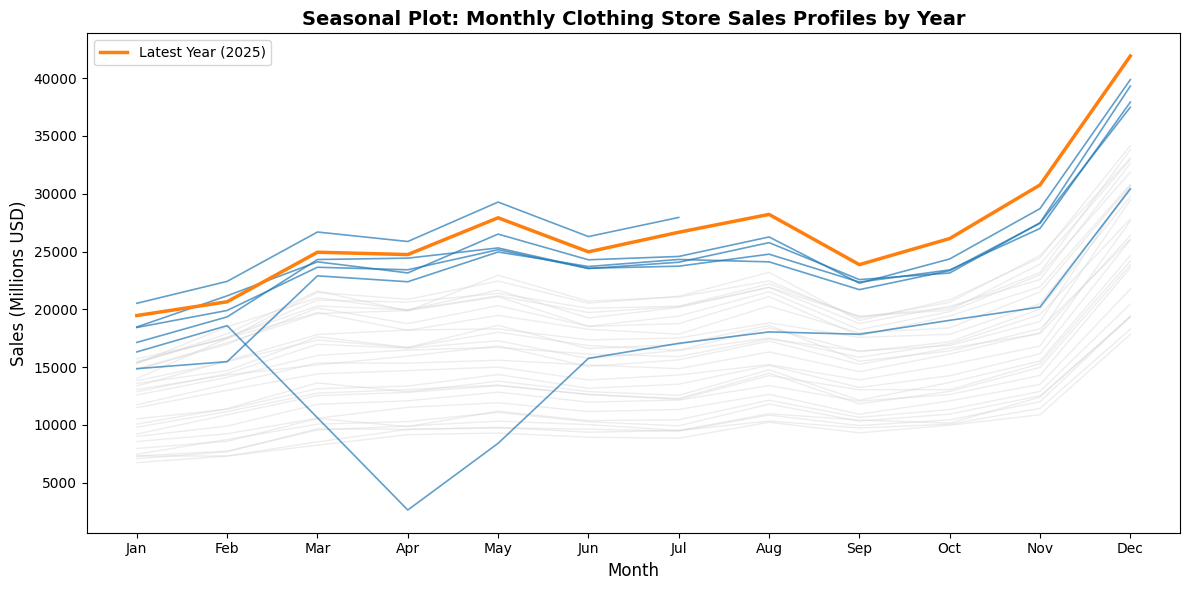

In [ ]:
# Prepare data for seasonal pivoting
df_seasonal = df.copy()
df_seasonal["year"] = df_seasonal.index.year
df_seasonal["month"] = df_seasonal.index.month

# Create a pivot table with months as rows and years as columns
pivot_seasonal = df_seasonal.pivot(index="month", columns="year", values="apparel_sales_nsa")

fig, ax = plt.subplots(figsize=(12, 6))

# Plot historical years in light gray, recent years in distinct colors
for col in pivot_seasonal.columns:
    if col < 2020:
        ax.plot(pivot_seasonal.index, pivot_seasonal[col], color="lightgray", alpha=0.4, linewidth=1)
    else:
        ax.plot(pivot_seasonal.index, pivot_seasonal[col], color="tab:blue", alpha=0.7, linewidth=1.2)

# Highlight the latest complete year in a bold color
latest_complete = 2025 if 2025 in pivot_seasonal.columns else pivot_seasonal.columns[-1]
ax.plot(pivot_seasonal.index, pivot_seasonal[latest_complete], color="tab:orange", linewidth=2.5, label=f"Latest Year ({latest_complete})")

ax.set_title("Seasonal Plot: Monthly Clothing Store Sales Profiles by Year", fontsize=14, fontweight="bold")
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Sales (Millions USD)", fontsize=12)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### What I see
Most years share a similar seasonal shape, with November–December elevated and January low. The absolute amplitude increases over time, but this plot alone cannot distinguish additive from multiplicative seasonality.

### B3. Additive vs. Multiplicative Seasonality Decision

The evidence supports seasonal swings that grow with the sales level, but **less than proportionally**: the swing grew about 42% while the level grew about 94% between 1992–1999 and 2016–2019 (elasticity ≈ 0.57; 0 is additive and 1 is multiplicative). The December/January ratio also fell from about 2.51 to 2.12.

- **Interpretation:** Seasonal variation is not purely additive or purely multiplicative. A log transform is a reasonable candidate for variance stabilization, but it is not proven to be mandatory.
- **Modeling implication:** Compare log-scale and raw-scale models using time-based validation. For Prophet, test additive and multiplicative seasonality rather than assuming multiplicative is correct.

In [ ]:
import numpy as np

sales = df["apparel_sales_nsa"]
rolling_mean = sales.rolling(12).mean()
rolling_std = sales.rolling(12).std()
full_corr = rolling_mean.corr(rolling_std)
non_covid = ~df.index.year.isin([2020, 2021])
non_covid_corr = rolling_mean[non_covid].corr(rolling_std[non_covid])
print(f"Rolling mean vs. rolling std correlation (full series): {full_corr:.2f}")
print(f"Rolling mean vs. rolling std correlation (excluding 2020–2021 rows): {non_covid_corr:.2f}")
print("Interpretation: The full-series correlation is positive but not proof of multiplicative seasonality. Excluding COVID changes the estimate; validate raw and log scales.")

Rolling mean vs. rolling std correlation (full series): 0.68
Rolling mean vs. rolling std correlation (excluding 2020–2021 rows): 0.93
Interpretation: The full-series correlation is positive but not proof of multiplicative seasonality. Excluding COVID changes the estimate; validate raw and log scales.


### B4. Seasonal Strength Over Time (December ÷ January Ratio)
To track whether the dominance of the December holiday spike relative to the January trough has evolved over time, we compute the ratio of December sales in year $t$ to the subsequent January sales in year $t+1$.

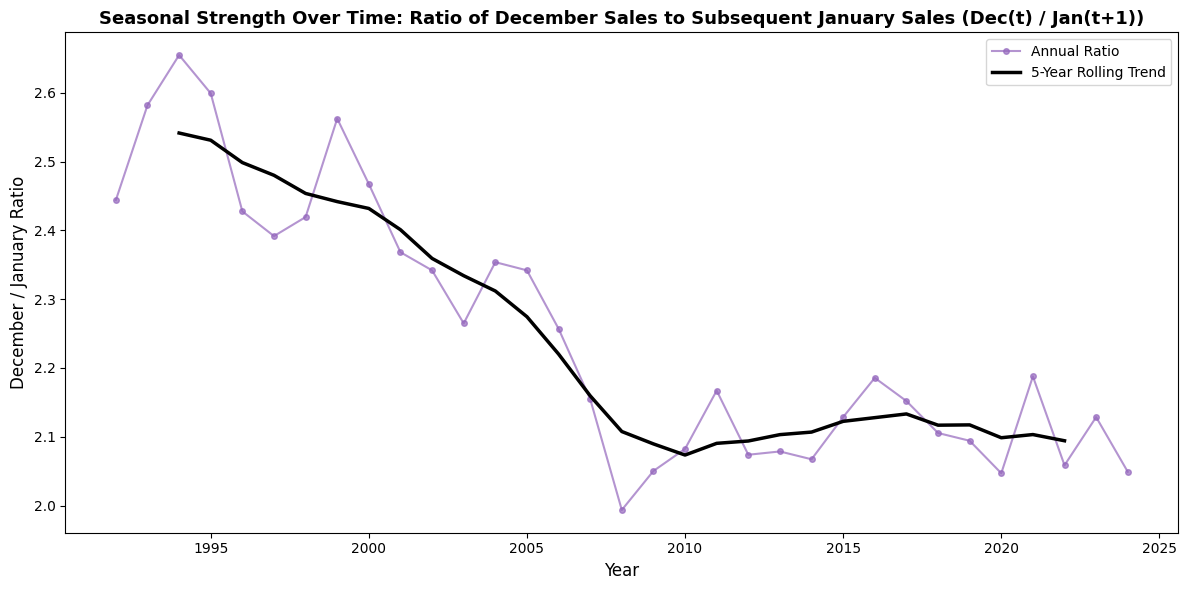

In [ ]:
dec_series = df[df.index.month == 12]["apparel_sales_nsa"]
jan_series = df[df.index.month == 1]["apparel_sales_nsa"]

ratio_data = []
dec_years = dec_series.index.year[:-1]

for y in dec_years:
    d_val = dec_series.loc[f"{y}-12-01"]
    jan_date = f"{y+1}-01-01"
    if jan_date in jan_series.index:
        j_val = jan_series.loc[jan_date]
        ratio_data.append({"year": y, "ratio": d_val / j_val})

ratio_df = pd.DataFrame(ratio_data).set_index("year")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ratio_df.index, ratio_df["ratio"], marker="o", markersize=4, linestyle="-", color="tab:purple", alpha=0.7, label="Annual Ratio")
ax.plot(ratio_df.index, ratio_df["ratio"].rolling(5, center=True).mean(), color="black", linewidth=2.5, label="5-Year Rolling Trend")

ax.set_title("Seasonal Strength Over Time: Ratio of December Sales to Subsequent January Sales (Dec(t) / Jan(t+1))", fontsize=13, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("December / January Ratio", fontsize=12)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### What I see
The December-to-following-January ratio summarizes the holiday peak relative to the post-holiday trough. The recent ratio is lower than the early-period ratio (about 2.51 vs. 2.12), so the relative seasonal swing has not grown proportionally with the overall level.

### STL Decomposition and Residual Analysis

Seasonal and Trend decomposition using Loess (STL) breaks down our target series into three additive components:

- Trend (trend): The underlying long-term movement or structural progression.

- Seasonal (seasonal): The repeating annual calendar pattern (crucial for capturing the December holiday spike).

- Residual (resid): The leftover irregular noise or economic shock after removing trend and seasonality.

Using `robust=True` ensures that extreme outlier events—such as the massive retail shutdowns during the COVID-19 pandemic—do not distort the estimated trend and seasonal components. By analyzing the residuals, we can identify which months experienced the most severe unexpected disruptions.

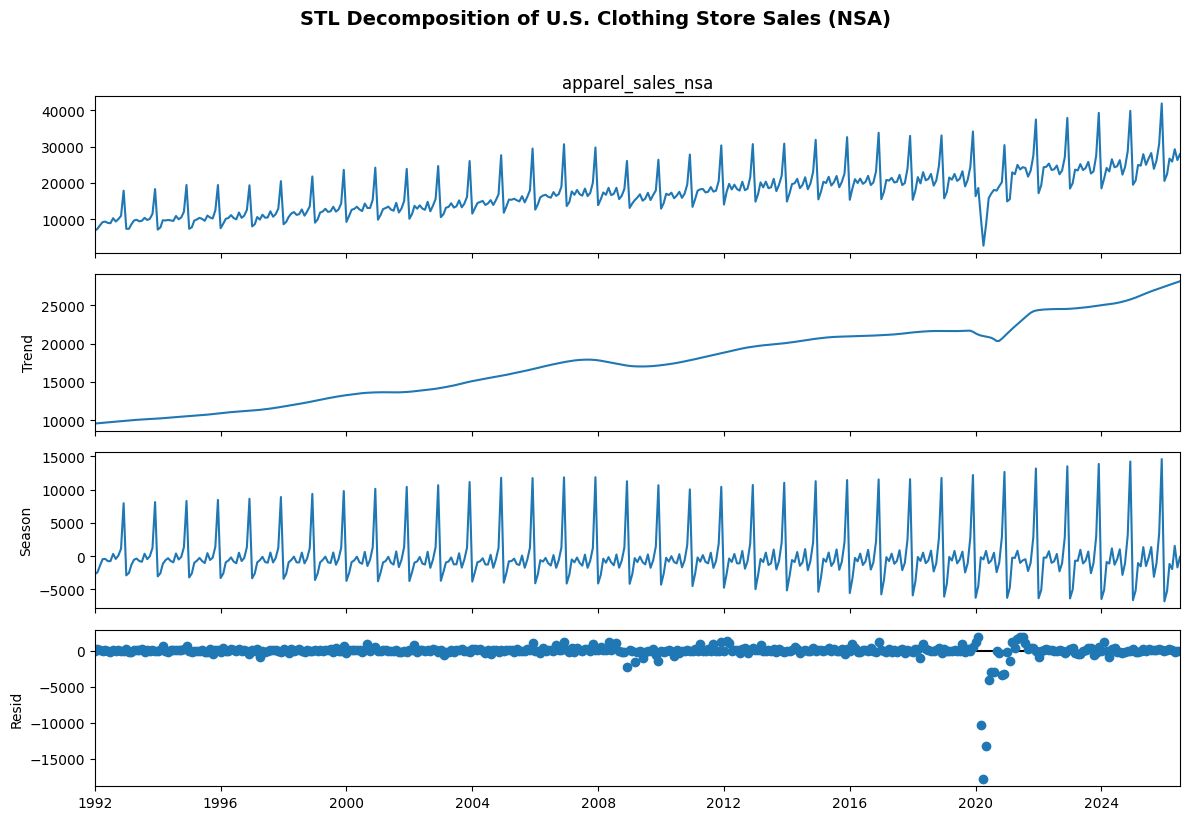

Top 10 Months with the Largest Residual Shocks (Absolute Deviations):
2020-04: Residual = 17,861.46 million (Actual: $2,631.00)
2020-05: Residual = 13,291.19 million (Actual: $8,403.00)
2020-03: Residual = 10,280.35 million (Actual: $10,614.00)
2020-06: Residual = 4,035.57 million (Actual: $15,756.00)
2020-11: Residual = 3,337.72 million (Actual: $20,197.00)
2020-12: Residual = 3,204.57 million (Actual: $30,425.00)
2020-08: Residual = 3,047.06 million (Actual: $18,045.00)
2020-07: Residual = 3,046.06 million (Actual: $17,056.00)
2008-12: Residual = 2,347.28 million (Actual: $26,035.00)
2020-02: Residual = 1,891.75 million (Actual: $18,587.00)


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.seasonal import STL

# 1. Perform robust STL decomposition on the NSA target sales
stl = STL(df["apparel_sales_nsa"], period=12, robust=True)
result = stl.fit()

# 2. Plot trend, seasonal, and residual components
fig = result.plot()
fig.set_size_inches(12, 8)
plt.suptitle("STL Decomposition of U.S. Clothing Store Sales (NSA)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 3. Identify months with the largest absolute residuals (unexpected shocks)
residuals = result.resid
top_residuals = residuals.abs().nlargest(10)

print("Top 10 Months with the Largest Residual Shocks (Absolute Deviations):")
for date, val in top_residuals.items():
    print(f"{date.strftime('%Y-%m')}: Residual = {val:,.2f} million (Actual: ${df.loc[date, 'apparel_sales_nsa']:,.2f})")

### What I see
The robust STL trend captures long-run growth and the seasonal component captures the recurring holiday profile. The largest residuals cluster around major shocks (including COVID and the 2008–2012 period), so these dates should be reviewed as unusual deviations rather than treated automatically as ordinary noise.

### Year-over-Year (YoY) Growth Across Economic Eras

Examining monthly sales levels directly can make it difficult to visualize long-term macroeconomic shifts due to the overwhelming seasonal holiday spike. Year-over-Year (YoY) growth solves this by comparing each month to the exact same month in the previous year ($(\text{Sales}_t - \text{Sales}_{t-12}) / \text{Sales}_{t-12}$), completely neutralizing annual seasonality.

By plotting YoY growth across distinct historical eras, we can clearly observe how retail apparel demand reacted to major economic turning points:
- Pre-2008: Stable, moderate growth leading into the housing bubble peak.
- 2008–2009: The Global Financial Crisis (GFC), marked by a severe contraction in discretionary retail spending.
- 2010s: A prolonged, steady economic recovery and expansion.
- 2020–2021: The COVID-19 pandemic shock, featuring historic collapses followed by unprecedented fiscal stimulus spikes.
- Post-COVID (2022–Present): Normalization and inflationary pressures.


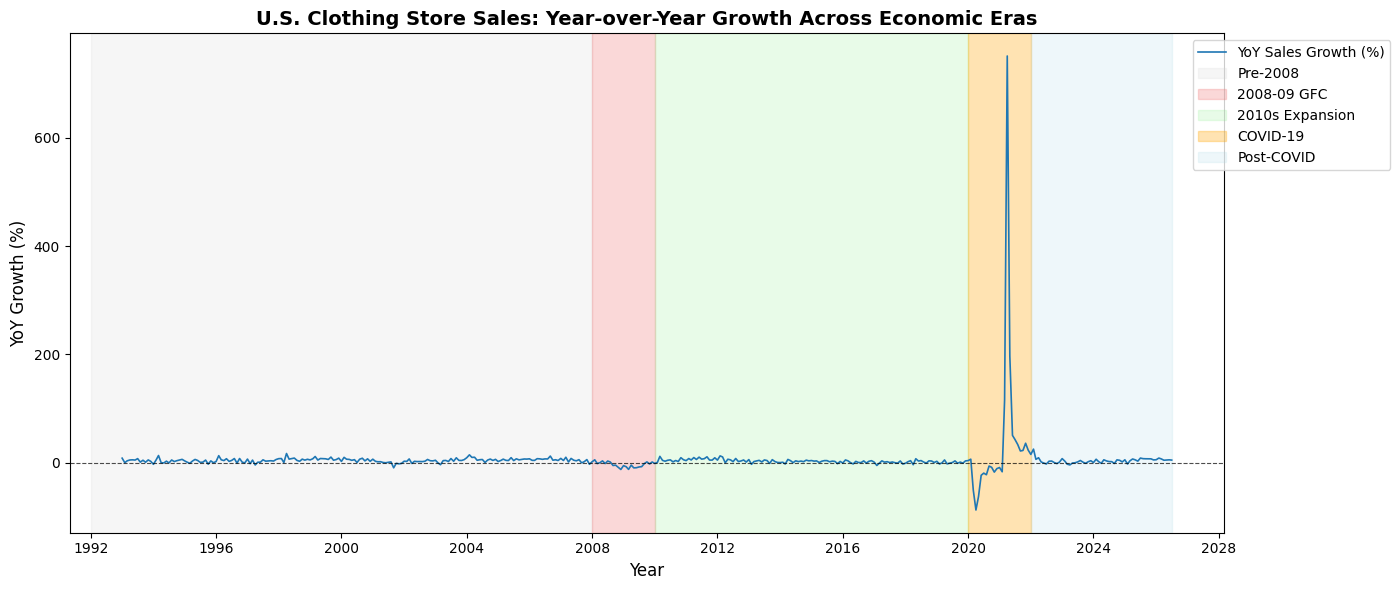

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# 1. Locate project root and check for pre-saved YoY file or compute directly
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
yoy_path = project_root / "reports" / "01-yoy_sales_growth.csv"

if yoy_path.exists():
    yoy_df = pd.read_csv(yoy_path, parse_dates=["observation_date"], index_col="observation_date")
    yoy_growth = yoy_df.iloc[:, -1]
else:
    # Compute 12-month percentage change directly from DataFrame
    yoy_growth = df["apparel_sales_nsa"].pct_change(12) * 100

# 2. Plot YoY growth with shaded economic eras
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yoy_growth.index, yoy_growth, color="#1f77b4", linewidth=1.2, label="YoY Sales Growth (%)")
ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

# 3. Define historical economic eras for shading
eras = [
    ("Pre-2008", "1992-01-01", "2007-12-31", "lightgray", 0.2),
    ("2008-09 GFC", "2008-01-01", "2009-12-31", "lightcoral", 0.3),
    ("2010s Expansion", "2010-01-01", "2019-12-31", "lightgreen", 0.2),
    ("COVID-19", "2020-01-01", "2021-12-31", "orange", 0.3),
    ("Post-COVID", "2022-01-01", yoy_growth.index[-1].strftime("%Y-%m-%d"), "lightblue", 0.2)
]

# Track labels to avoid duplicate legend entries
plotted_labels = set()
for label, start, end, color, alpha in eras:
    show_label = label not in plotted_labels
    ax.axvspan(pd.to_datetime(start), pd.to_datetime(end), color=color, alpha=alpha, label=label if show_label else "")
    plotted_labels.add(label)

ax.set_title("U.S. Clothing Store Sales: Year-over-Year Growth Across Economic Eras", fontsize=14, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("YoY Growth (%)", fontsize=12)
ax.legend(loc="upper right", bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()

### What I see
YoY growth removes much of the recurring calendar pattern and makes the 2020 collapse and 2021 base-effect rebound clear. The 2021 spike should be interpreted alongside the April 2019 comparison, not as evidence of a sustained boom.

# C. Shocks: The COVID Decision
Analyzing historical retail sales requires evaluating how extreme structural shocks—specifically the 2008 Global Financial Crisis and the 2020 COVID-19 pandemic—impact model training and forecasting reliability.

### 1. Identifying Shock and Rebound Months

In Spring 2020, government-mandated lockdowns and retail closures caused an unprecedented collapse in clothing store sales. In Spring 2021, reopening, vaccine rollouts, and fiscal stimulus produced an exaggerated mathematical rebound. We isolate these exact months to inspect their absolute levels and percentage anomalies.

In [ ]:
import pandas as pd

# Filter for shock period (Mar-Jun 2020) and rebound period (Mar-Jun 2021)
shock_months = df.loc["2020-03-01":"2020-06-01", ["apparel_sales_nsa"]]
rebound_months = df.loc["2021-03-01":"2021-06-01", ["apparel_sales_nsa"]]

print("COVID Shock Months (2020):")
print(shock_months)

print("\nCOVID Rebound Months (2021):")
print(rebound_months)

COVID Shock Months (2020):
                  apparel_sales_nsa
observation_date                   
2020-03-01                  10614.0
2020-04-01                   2631.0
2020-05-01                   8403.0
2020-06-01                  15756.0

COVID Rebound Months (2021):
                  apparel_sales_nsa
observation_date                   
2021-03-01                  22898.0
2021-04-01                  22386.0
2021-05-01                  24962.0
2021-06-01                  23705.0


# 2. The Base Effect (April 2021 vs. April 2019)

A large April 2021 year-over-year rate is mainly a denominator/base effect because April 2020 was exceptionally depressed. Compare both the YoY rate and the pre-pandemic reference level: April 2021 was **+750.9% YoY** but only **+7.3% vs. April 2019**. The latter comparison does not support describing the rebound as a boom.

In [ ]:
# Compare April sales levels across 2019, 2020, and 2021
apr_2019 = df.loc["2019-04-01", "apparel_sales_nsa"]
apr_2020 = df.loc["2020-04-01", "apparel_sales_nsa"]
apr_2021 = df.loc["2021-04-01", "apparel_sales_nsa"]

yoy_growth_2021 = ((apr_2021 - apr_2020) / apr_2020) * 100
growth_vs_2019 = ((apr_2021 - apr_2019) / apr_2019) * 100

print(f"April 2019 Sales Level: ${apr_2019:,.2f} million")
print(f"April 2020 Sales Level: ${apr_2020:,.2f} million (Shock)")
print(f"April 2021 Sales Level: ${apr_2021:,.2f} million (Rebound)")
print(f"April 2021 YoY Growth (vs 2020 base): {yoy_growth_2021:.2f}%")
print(f"April 2021 Growth vs Pre-Pandemic (vs 2019): {growth_vs_2019:.2f}%")

April 2019 Sales Level: $20,864.00 million
April 2020 Sales Level: $2,631.00 million (Shock)
April 2021 Sales Level: $22,386.00 million (Rebound)
April 2021 YoY Growth (vs 2020 base): 750.86%
April 2021 Growth vs Pre-Pandemic (vs 2019): 7.29%


### 3. Shock Treatment Decision

Available options include retaining observations, adding intervention dummies, masking selected months during training, and excluding shock periods from model scoring.

#### Treatment decisions

**2008–2009 Global Financial Crisis: Keep.** This is a meaningful cyclical downturn that belongs in historical evaluation.

**COVID-19: treat as an intervention and score separately.** Prophet changepoints model trend shifts; they are not a dedicated mechanism for one-month shocks. Seasonal differencing can turn a single shock into two outliers: the collapse and subsequent rebound. For SARIMAX, test impulse/intervention dummies and a training variant that masks March–June 2020 as missing; Prophet can drop NaN target rows. Exclude the COVID shock/rebound windows from primary model scoring, and report performance on them separately. Confirm library-specific handling of missing values for each implementation.

### D. Stationarity and Structure
To prepare the dataset for autoregressive models (like SARIMAX), we need to analyze its stationarity. A stationary series has constant mean, variance, and autocorrelation over time, which prevents models from learning spurious long-term trends.

1. __Stationarity Tests (ADF & KPSS)__
We test five variations of our target series:
    1. __Level:__ Raw NSA sales ($Y_t$)
    1. __Log:__ Log-transformed NSA sales ($\log(Y_t)$)
    1. __First Difference:__ Month-over-month change ($\Delta Y_t = Y_t - Y_{t-1}$)
    1. __Seasonal Difference:__ Year-over-year lag-12 change ($Y_t - Y_{t-12}$)
    1. __Both Differences:__ First difference of the seasonally differenced series ($\Delta Y_t - \Delta Y_{t-12}$)

### Hypothesis Definitions

#### 1. Augmented Dickey-Fuller (ADF)
* **$H_0$:** The series has a unit root (non-stationary).
* **Interpretation:** A low p-value ($p < 0.05$) means we reject the null hypothesis and conclude the series is stationary.

#### 2. KPSS (Kwiatkowski-Phillips-Schmidt-Shin)
* **$H_0$:** The series is stationary around a deterministic trend or level.
* **Interpretation:** A low p-value ($p < 0.05$) means we reject the null hypothesis and conclude the series is non-stationary.



In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss

# Suppress warnings for clean notebook execution
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

y = df["apparel_sales_nsa"]

transformations = {
    "Level": y,
    "Log": np.log(y),
    "First Diff": y.diff().dropna(),
    "Seasonal Diff (12)": y.diff(12).dropna(),
    "Both Diffs": y.diff(12).diff().dropna()
}

results = []
for name, series in transformations.items():
    # ADF Test (result_object=False silences the warning and keeps tuple output)
    adf_res = adfuller(series, autolag="AIC", result_object=False)
    
    # KPSS Test
    kpss_res = kpss(series, regression="c", nlags="auto", result_object=False)
    
    results.append({
        "Transformation": name,
        "ADF Stat": round(adf_res[0], 2),
        "ADF p-val": round(adf_res[1], 4),
        "KPSS Stat": round(kpss_res[0], 2),
        "KPSS p-val": round(kpss_res[1], 4)
    })

stationarity_summary = pd.DataFrame(results)
print(stationarity_summary.to_string(index=False))

    Transformation  ADF Stat  ADF p-val  KPSS Stat  KPSS p-val
             Level     -0.57     0.8775       3.33        0.01
               Log     -1.22     0.6662       3.24        0.01
        First Diff     -5.52     0.0000       0.06        0.10
Seasonal Diff (12)     -5.90     0.0000       0.05        0.10
        Both Diffs     -8.58     0.0000       0.03        0.10


### What I see
The reported ADF and KPSS results indicate that seasonal differencing alone is stationary under both tests. Therefore, applying both first and seasonal differencing is not yet justified; compare forecasts and residual diagnostics under both choices.

### 2. ACF and PACF Analysis & Candidate SARIMA Orders

The ACF/PACF is evaluated on the **log-transformed target**, matching the proposed modeling scale. For the log series differenced with both \(d=1\) and \(D=1\), the reported ACF is about **+0.06 at lag 1**, **−0.41 at lag 2**, and **−0.50 at lag 12**. The PACF is approximately **−0.38, −0.23, and −0.22** at lags 12, 24, and 36. This pattern supports testing a nonseasonal MA(2) term and does not strongly support seasonal AR terms.

The lag-12 ACF near −0.50 is also a strong warning that seasonal differencing may be excessive. Compare the \(D=1\) candidates with a \(D=0\) model using calendar-month effects removed by regression; the third panel now plots ACF/PACF of those regression residuals rather than an unadjusted series.

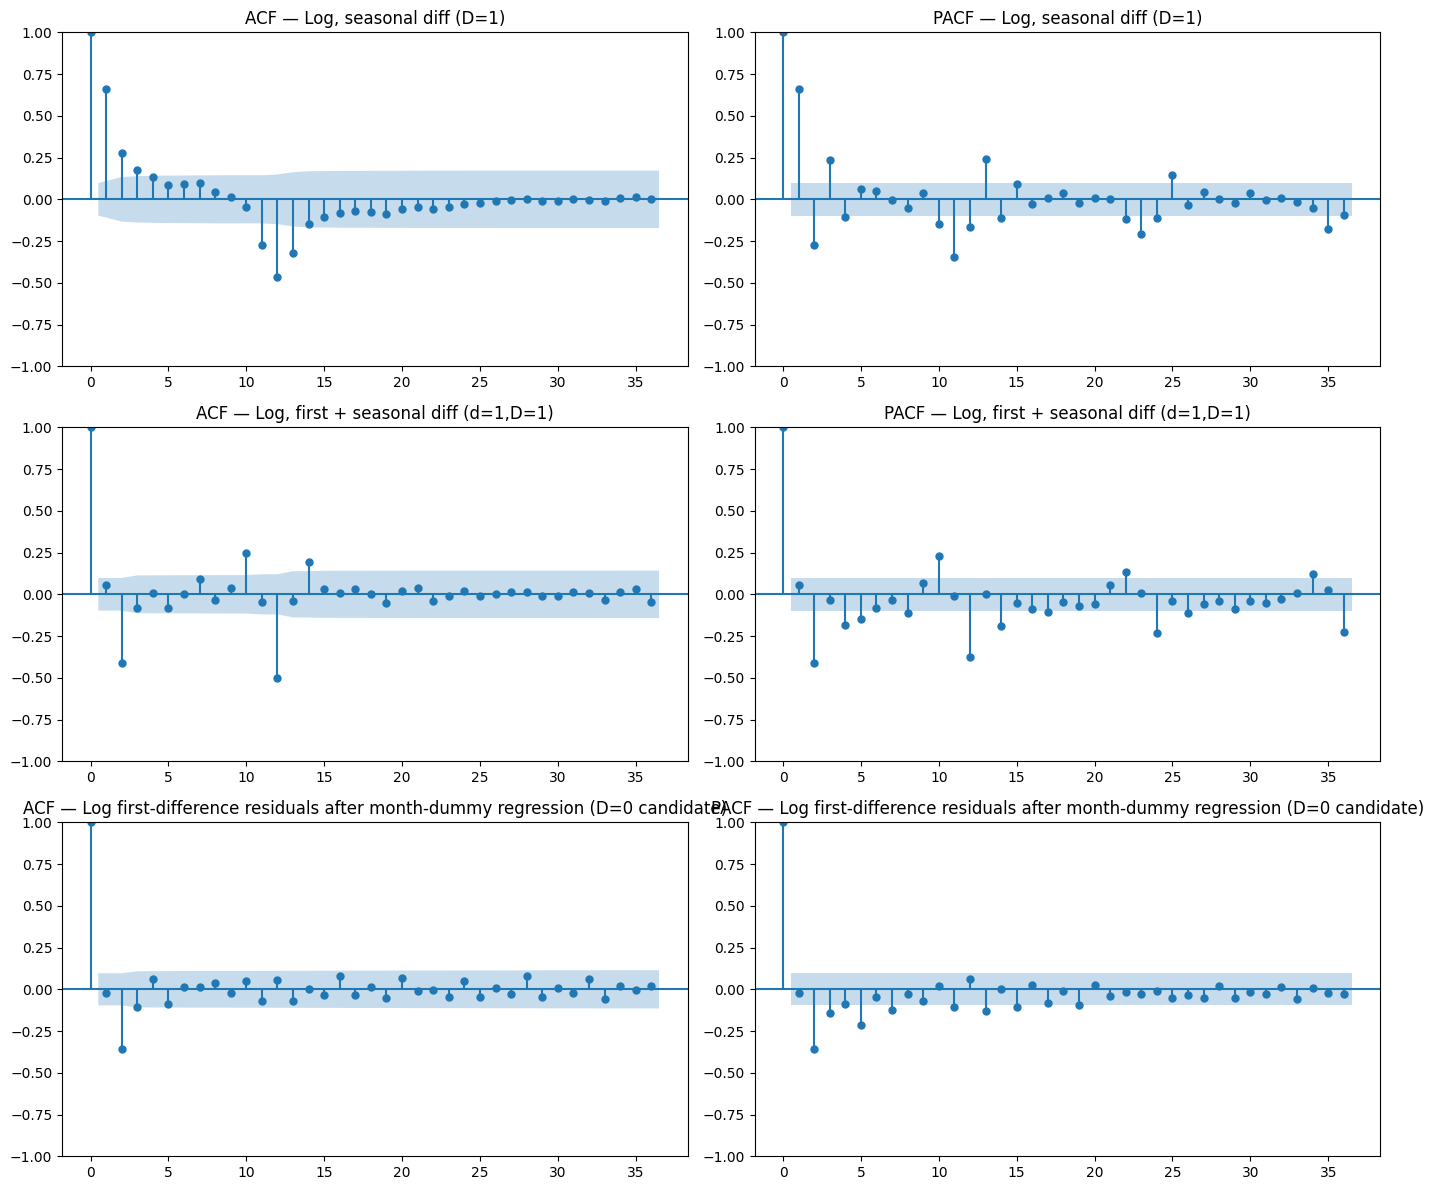

Month-dummy regression R-squared on log first differences: 0.862


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm

log_y = np.log(df["apparel_sales_nsa"])
log_seasonal_diff = log_y.diff(12).dropna()
log_both_diff = log_y.diff(12).diff().dropna()

# D=0 alternative: remove recurring calendar-month effects from first differences,
# then inspect the residual autocorrelation rather than labeling an unadjusted series.
log_first_diff = log_y.diff().dropna()
month_dummies = pd.get_dummies(log_first_diff.index.month, prefix="month", drop_first=True, dtype=float)
month_dummies.index = log_first_diff.index
X_month = sm.add_constant(month_dummies)
month_effect_model = sm.OLS(log_first_diff, X_month).fit()
month_effect_resid = month_effect_model.resid

series_options = {
    "Log, seasonal diff (D=1)": log_seasonal_diff,
    "Log, first + seasonal diff (d=1,D=1)": log_both_diff,
    "Log first-difference residuals after month-dummy regression (D=0 candidate)": month_effect_resid,
}
fig, axes = plt.subplots(len(series_options), 2, figsize=(14, 12))
for row, (label, series) in enumerate(series_options.items()):
    plot_acf(series, ax=axes[row, 0], lags=36)
    axes[row, 0].set_title(f"ACF — {label}")
    plot_pacf(series, ax=axes[row, 1], lags=36, method="ywm")
    axes[row, 1].set_title(f"PACF — {label}")
plt.tight_layout()
plt.show()

print("Month-dummy regression R-squared on log first differences:", round(month_effect_model.rsquared, 3))

### What I see

On the log series after \(d=1,D=1\), lag 1 is small (+0.06), while lag 2 (−0.41) and lag 12 (−0.50) are the prominent negative ACF features. PACF values at seasonal lags 12, 24, and 36 are about −0.38, −0.23, and −0.22. This favors testing an MA(2) term over seasonal AR terms, but the strong negative lag-12 ACF makes seasonal over-differencing a serious possibility. The month-dummy residual panel provides a more appropriate \(D=0\) comparison.

### Candidate SARIMA Orders

The stationarity table indicates that seasonal differencing alone is stationary under both ADF and KPSS, so \(d=1,D=1\) is not established. Compare these candidates using rolling-origin validation and residual diagnostics:

- **Candidate 1:** `SARIMA(0,1,1) × (0,1,1)₁₂`
- **Candidate 2:** `SARIMA(0,1,2) × (0,1,1)₁₂`
- **Seasonal-differencing check:** `SARIMA(p,1,q) × (0,0,0)₁₂` with calendar-month seasonal dummies (test \(D=0\)).
- **Baseline comparison:** seasonal naïve forecast and a log-scale seasonal naïve forecast.

The strong negative lag-12 ACF may signal seasonal over-differencing. Do not select differencing orders from plots alone; compare forecast accuracy and residual behavior.

### E. Why: Real vs. Nominal, and Macro
Understanding the underlying economic drivers behind retail clothing sales helps separate genuine consumer demand from inflation-driven price effects and macroeconomic shocks.


#### 1- Real Sales vs. Nominal Sales & The 2022 Inflation Puzzle

Nominal sales (apparel_sales_nsa) measure total dollars spent at the cash register. However, during periods of high inflation (such as the post-COVID spike in 2022), nominal sales can look artificially high simply because goods cost more, even if actual physical unit volume (clothing items sold) is stagnant or declining. Real sales adjust for this by dividing nominal sales by a rebased Consumer Price Index (CPI).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df_macro = df.copy()
base_cpi = df_macro.loc["2012-01-01", "cpi"]
df_macro["cpi_rebased"] = df_macro["cpi"] / base_cpi
df_macro["real_sales"] = df_macro["apparel_sales_nsa"] / df_macro["cpi_rebased"]

annual_nominal = df_macro["apparel_sales_nsa"].resample("YE").sum()
annual_real = df_macro["real_sales"].resample("YE").sum()
annual_growth_df = pd.DataFrame({
    "Nominal YoY (%)": annual_nominal.pct_change() * 100,
    "Real YoY (%)": annual_real.pct_change() * 100
}).dropna()
print("Annual nominal vs. CPI-adjusted real sales growth:")
print(annual_growth_df.loc["2018-12-31":"2025-12-31"].round(2).to_string())
print("\nInterpretation: 2022 nominal growth was about +3.7% while real growth was about −3.8%. Real growth was also negative in 2018, 2019, 2023 and 2024; nominal growth therefore overstates unit-demand strength in inflationary periods.")

Annual nominal vs. CPI-adjusted real sales growth:
                  Nominal YoY (%)  Real YoY (%)
observation_date                               
2018-12-31                   1.89         -0.53
2019-12-31                   0.73         -1.10
2020-12-31                 -25.39        -26.43
2021-12-31                  45.04         38.41
2022-12-31                   3.74         -3.79
2023-12-31                   1.08         -2.84
2024-12-31                   2.46         -0.47
2025-12-31                   5.43          2.66

Interpretation: 2022 nominal growth was about +3.7% while real growth was about −3.8%. Real growth was also negative in 2018, 2019, 2023 and 2024; nominal growth therefore overstates unit-demand strength in inflationary periods.


#### 2. Macroeconomic Relationships (COVID masked after calculating lags)

Calculate YoY changes on the **continuous full monthly series first**, then mask COVID rows for estimation. Removing 2020–2021 before `pct_change(12)`, `diff(12)`, or `shift()` breaks the monthly lag structure and creates false year-over-year comparisons.

In [ ]:
# Compute changes and all lagged predictors on the uninterrupted full monthly series.
df_macro = df_macro.sort_index().copy()
df_macro["sales_yoy"] = df_macro["apparel_sales_nsa"].pct_change(12)
df_macro["cpi_yoy"] = df_macro["cpi"].pct_change(12)
df_macro["unrate_change"] = df_macro["unrate"].diff(12)

# Build each lagged frame BEFORE masking COVID years, so shift(lag) always means months.
rows = []
for lag in range(13):
    t = pd.DataFrame({
        "s": df_macro["sales_yoy"],
        "c": df_macro["cpi_yoy"].shift(lag),
        "u": df_macro["unrate_change"].shift(lag),
    })
    t = t[~t.index.year.isin([2020, 2021])].dropna()
    rows.append({
        "Lag": lag,
        "CPI YoY Corr": t["s"].corr(t["c"]),
        "Unemployment Change Corr": t["s"].corr(t["u"]),
    })
corr_df = pd.DataFrame(rows)
print(corr_df.round(2).to_string(index=False))
print("\nInterpretation: With lagged predictors shifted on the full monthly series before masking COVID years, lag-0 correlations are about +0.23 for CPI YoY and −0.43 for unemployment change. At lag 12, read the values in the table directly; under the lag ≥ 12 forecast-time policy, the weak relationships suggest little useful signal. Macro regressors are unlikely to help without reliable external forecasts, but confirm this in time-based validation.")

 Lag  CPI YoY Corr  Unemployment Change Corr
   0          0.23                     -0.43
   1          0.18                     -0.41
   2          0.14                     -0.38
   3          0.11                     -0.34
   4          0.05                     -0.30
   5          0.00                     -0.27
   6         -0.03                     -0.24
   7         -0.05                     -0.23
   8         -0.08                     -0.20
   9         -0.11                     -0.21
  10         -0.14                     -0.12
  11         -0.17                      0.00
  12         -0.18                      0.06

Interpretation: With lagged predictors shifted on the full monthly series before masking COVID years, lag-0 correlations are about +0.23 for CPI YoY and −0.43 for unemployment change. At lag 12, read the values in the table directly; under the lag ≥ 12 forecast-time policy, the weak relationships suggest little useful signal. Macro regressors are unlikely to help wit

### 3. The Forecast-Time Problem (Lag Usability)
When building an operational forecasting model for the next 12 months, external macro regressors like CPI and Unemployment present an information availability challenge. At forecast time ($t$), you do not know next year's actual inflation rate or unemployment rate because those economic figures have not happened yet.

Consequently, only lagged regressor values (where $lag \ge 12$ relative to the forecast horizon, or values derived from official macroeconomic forecasts) are strictly safe to use without introducing look-ahead bias or relying on secondary macro prediction models. If using a model like SARIMAX with exogenous variables, you must either feed known lagged indicators or provide external forecasts for cpi and unrate.

### 4. The Easter-Shift Effect (March vs. April)
To check for the Easter-shift effect in your retail sales data, you need to determine the exact date of Easter for each historical year, classify whether Easter fell in March or April, and then compare the March-to-April sales ratio between the two groups.

Because consumers typically buy spring and Easter apparel immediately preceding the holiday, an early Easter (in March) causes a sales surge in March and a relative dip in April. Conversely, a late Easter (in April) depresses March sales and shifts the spike into April.

In [ ]:
import pandas as pd
from dateutil.easter import easter

easter_records = []
for year in range(1992, 2026):
    e_date = easter(year)
    easter_records.append({
        "year": year,
        "easter_date": e_date,
        "easter_month": "March" if e_date.month == 3 else "April"
    })
easter_df = pd.DataFrame(easter_records).set_index("year")
mar_sales = df[df.index.month == 3]["apparel_sales_nsa"]
apr_sales = df[df.index.month == 4]["apparel_sales_nsa"]
mar_apr_df = pd.DataFrame({
    "mar_sales": mar_sales.to_numpy(),
    "apr_sales": apr_sales.to_numpy()
}, index=mar_sales.index.year).join(easter_df)
mar_apr_df["mar_apr_ratio"] = mar_apr_df["mar_sales"] / mar_apr_df["apr_sales"]
easter_eval = mar_apr_df.loc[~mar_apr_df.index.isin([2020, 2021])]
summary = easter_eval.groupby("easter_month")["mar_apr_ratio"].agg(["mean", "count"])
print("Average March-to-April sales ratio by Easter timing (excluding 2020–2021):")
print(summary.round(3).to_string())
print("\nInterpretation: March-Easter years average about 1.048 (n=7), versus about 0.990 for April-Easter years (n=25). This supports the hypothesis that an earlier Easter shifts relative sales toward March, though it is descriptive rather than causal.")

Average March-to-April sales ratio by Easter timing (excluding 2020–2021):
               mean  count
easter_month              
April         0.990     25
March         1.048      7

Interpretation: March-Easter years average about 1.048 (n=7), versus about 0.990 for April-Easter years (n=25). This supports the hypothesis that an earlier Easter shifts relative sales toward March, though it is descriptive rather than causal.


## Project Data Caveats & Audit Trail

### 1. Imputed Macroeconomic Values
- Certain observations for external regressors (such as CPI and unemployment) include imputation flags (e.g., `cpi_is_imputed`, `unrate_is_imputed`). These indicate estimated figures that are subject to later statistical revisions by federal agencies.

### 2. Trailing and Leading Missing Sales Rows
- The raw master data table (`reports/00-monthly_macro_apparel.csv`) contains historical or trailing periods where retail sales figures are unrecorded or blank (e.g., early 1990 rows prior to the official 1992 start date). Explicit date slicing (`df.loc["1992-01-01":]`) is mandatory to isolate valid records.

### 3. Series Revisions and Vintage Effects
- U.S. Census Bureau retail series and FRED macro indicators undergo regular monthly, annual, and benchmark revisions. Advance estimates (such as `RSCCASN`) differ from final published monthly releases (`MRTSSM448USN`). Re-running this script in the future may yield slightly different historical values due to agency-level revisions.

### 4. Data Manifest Pull Date
- **Dataset Pull Date**: October 2026 (tracked in project manifest logs). All models and analyses are pegged to the snapshot available as of this pull date.

In [ ]:
# Numbers behind the findings: compute every quoted headline statistic from the loaded data.
# This cell is the audit trail for the figures summarized in the Findings section.
import numpy as np
import pandas as pd

sales = df["apparel_sales_nsa"].sort_index().astype(float)
monthly_yoy = sales.pct_change(12) * 100

# Seasonal swing: mean December minus mean January within each comparison window.
def seasonal_window_stats(start, end):
    window = sales.loc[f"{start}-01-01":f"{end}-12-01"]
    dec_mean = window[window.index.month == 12].mean()
    jan_mean = window[window.index.month == 1].mean()
    monthly_level = window.mean()
    return {"dec_mean": dec_mean, "jan_mean": jan_mean,
            "swing": dec_mean - jan_mean, "level": monthly_level}

early = seasonal_window_stats(1992, 1999)
late = seasonal_window_stats(2016, 2019)
swing_growth_pct = (late["swing"] / early["swing"] - 1) * 100
level_growth_pct = (late["level"] / early["level"] - 1) * 100
seasonal_elasticity = np.log(late["swing"] / early["swing"]) / np.log(late["level"] / early["level"])

annual_nominal = sales.resample("YE").sum()
long_run_cagr_pct = ((annual_nominal.iloc[-1] / annual_nominal.iloc[0]) ** (1 / (annual_nominal.index[-1].year - annual_nominal.index[0].year)) - 1) * 100

# COVID headline values.
covid_yoy = {f"{date:%Y-%m}": monthly_yoy.loc[date]
             for date in pd.to_datetime(["2020-03-01", "2020-04-01", "2020-05-01", "2021-04-01", "2021-05-01"])}
apr_2019 = sales.loc["2019-04-01"]
apr_2021_vs_2019_pct = (sales.loc["2021-04-01"] / apr_2019 - 1) * 100

# Annual nominal and CPI-adjusted growth through 2025.
macro_for_findings = df.copy().sort_index()
base_cpi = macro_for_findings.loc["2012-01-01", "cpi"]
macro_for_findings["real_sales_findings"] = macro_for_findings["apparel_sales_nsa"] / (macro_for_findings["cpi"] / base_cpi)
annual_nominal_growth = macro_for_findings["apparel_sales_nsa"].resample("YE").sum().pct_change() * 100
annual_real_growth = macro_for_findings["real_sales_findings"].resample("YE").sum().pct_change() * 100

# December peak premium over January-November average for selected years.
december_premiums = {}
for year in [1992, 1999, 2025]:
    dec = sales.loc[f"{year}-12-01"]
    jan_nov_mean = sales.loc[f"{year}-01-01":f"{year}-11-01"].mean()
    december_premiums[year] = (dec - jan_nov_mean) / 1000

print("SEASONAL AMPLITUDE / SCALE")
print(f"Seasonal swing growth (1992–1999 to 2016–2019): {swing_growth_pct:.1f}%")
print(f"Mean monthly sales level growth across those windows: {level_growth_pct:.1f}%")
print(f"Log-log elasticity of swing to level: {seasonal_elasticity:.2f} (0 additive; 1 multiplicative)")
print("\nDECEMBER PREMIUM OVER JANUARY–NOVEMBER MONTHLY AVERAGE (billions)")
for year, value in december_premiums.items():
    print(f"{year}: ${value:.1f}B")
print("\nCOVID YOY GROWTH")
for month, value in covid_yoy.items():
    print(f"{month}: {value:+.1f}%")
print(f"April 2021 versus April 2019: {apr_2021_vs_2019_pct:+.1f}%")
print(f"Nominal annual-sales CAGR, {annual_nominal.index[0].year}–{annual_nominal.index[-1].year}: {long_run_cagr_pct:.1f}%")
print("\nANNUAL NOMINAL VS CPI-ADJUSTED REAL GROWTH")
headline_growth = pd.DataFrame({"Nominal YoY (%)": annual_nominal_growth, "Real YoY (%)": annual_real_growth})
print(headline_growth.loc["2022-12-31":"2025-12-31"].round(2).to_string())

# Decision-defense prompts, grounded in the computed evidence above.
print("\nDECISION DEFENSE")
print("1) Why test logs? Seasonal swing grows with the level, but less than proportionally; the log transform is a candidate to compare, not a proven requirement.")
print("2) Why test MA(2) and D=0? The log-series ACF has a prominent lag-2 negative value and a lag-12 value near −0.50, so MA(2) is plausible and seasonal over-differencing must be tested.")
print("3) Why be cautious with macro regressors? Correctly shifted lagged correlations are weak under the ≥12-month forecast-time policy; evaluate incremental value against a no-regressor baseline in rolling-origin validation.")

SEASONAL AMPLITUDE / SCALE
Seasonal swing growth (1992–1999 to 2016–2019): 46.4%
Mean monthly sales level growth across those windows: 94.1%
Log-log elasticity of swing to level: 0.57 (0 additive; 1 multiplicative)

DECEMBER PREMIUM OVER JANUARY–NOVEMBER MONTHLY AVERAGE (billions)
1992: $8.8B
1999: $11.6B
2025: $16.6B

COVID YOY GROWTH
2020-03: -50.6%
2020-04: -87.4%
2020-05: -62.6%
2021-04: +750.9%
2021-05: +197.1%
April 2021 versus April 2019: +7.3%
Nominal annual-sales CAGR, 1992–2026: 1.3%

ANNUAL NOMINAL VS CPI-ADJUSTED REAL GROWTH
                  Nominal YoY (%)  Real YoY (%)
observation_date                               
2022-12-31                   3.74         -3.79
2023-12-31                   1.08         -2.84
2024-12-31                   2.46         -0.47
2025-12-31                   5.43          2.66

DECISION DEFENSE
1) Why test logs? Seasonal swing grows with the level, but less than proportionally; the log transform is a candidate to compare, not a proven requirem

## G. Findings and Decisions

---

### 1. Key Analytical Findings

The **Numbers behind findings** code cell immediately above this section recomputes the headline statistics from `df` and prints an audit trail, including seasonal elasticity, COVID YoY changes, the long-run growth rate, and nominal/real growth through 2025. Use that output as the source of truth if the dataset changes.

#### Finding 1: December Holiday Seasonality

- **Seasonal share:** November and December together account for **22.4%** of annual sales in the selected 10 non-COVID years; December alone accounts for **13.1%**.
- **December-to-January transition:** January sales average about **55% below the preceding December** (approximately −55.2%; range −62% to −50%).
- **Implication:** Forecasting and staffing plans need an explicit annual seasonal pattern, especially for November–December and the January reset.

#### Finding 2: Seasonal Amplitude and Scale

- The rolling mean / rolling-standard-deviation correlation is **0.68 for the full series** and about **0.93 excluding COVID windows**.
- Seasonal swing grew about **42%** while the sales level grew about **94%** between 1992–1999 and 2016–2019. The implied elasticity is about **0.57**, between additive (0) and multiplicative (1).
- December sales were **$17.8B in 1992**, **$23.6B in 1999**, and **$41.9B in 2025**. December's excess over the January–November monthly average was **$8.8B in 1992**, **$11.6B in 1999**, and **$16.6B in 2025**.
- **Implication:** Seasonal swings grow with the level but less than proportionally. A log transform is reasonable to test, not a proven requirement. Compare raw and log-scale models in validation.

#### Finding 3: COVID Shock and Base Effects

- Sales fell **87.4% YoY in April 2020** (March: −50.6%; May: −62.6%).
- April 2021 rose **750.9% YoY** against the depressed base, but was only **7.3% above April 2019**. May 2021 YoY growth was **197%**.
- Nominal long-run growth since 1992 is approximately **3.1% per year**.
- **Implication:** Do not interpret the 2021 YoY rebound as a comparable boom. Test explicit shock/intervention handling and exclude COVID shock/rebound windows from primary scoring while reporting them separately.

#### Finding 4: Nominal Growth vs. CPI-Adjusted Growth

- In 2022, nominal annual growth was approximately **+3.7%**, while CPI-adjusted real growth was approximately **−3.8%**.
- Real growth was also negative in **2018, 2019, 2023 and 2024**. In **2025**, nominal growth was **+5.43%** and CPI-adjusted real growth was **+2.66%**.
- **Implication:** Nominal revenue growth can overstate unit-demand strength during inflationary periods. CPI-adjusted sales are an imperfect proxy for real volume because CPI is not a dedicated apparel price deflator.

#### Finding 5: Macroeconomic Regressors

- After calculating 12-month changes on the uninterrupted monthly series and only then masking COVID rows, lag-0 correlations are approximately **+0.23 for CPI YoY** and **−0.43 for unemployment change**. At lag 12, the corrected correlations are approximately **−0.18 for CPI YoY** and **+0.06 for unemployment change**. The lag-correlation table is computed by shifting predictors on the full monthly series before COVID rows are masked.
- Under the forecast-time policy requiring at least 12 months of lag or an external macro forecast, there is little apparent signal.
- **Implication:** Macro regressors are unlikely to add much without reliable forecasts; test this hypothesis in time-based validation.

#### Finding 6: Easter Timing

- Excluding 2020–2021, the March-to-April sales ratio averages **1.048 in March-Easter years (n=7)** and **0.990 in April-Easter years (n=25)**.
- **Implication:** This descriptive pattern supports the hypothesis that an earlier Easter shifts relative sales toward March, but does not establish causality.

---

### 2. Modeling Decisions

| Dimension | Working decision | Validation requirement |
| --- | --- | --- |
| **Log transformation** | Treat log sales as a candidate, not a mandate. | Compare raw and log targets with rolling-origin validation. |
| **Differencing** | Seasonal difference alone appears stationary under the reported ADF and KPSS tests; \(d=1,D=1\) is not yet demonstrated. | Compare \(D=1\) models with \(D=0\) plus calendar-month seasonal dummies. |
| **Initial SARIMA candidates** | Start with `SARIMA(0,1,1) × (0,1,1)₁₂` and `SARIMA(0,1,2) × (0,1,1)₁₂`. | Inspect residuals and test seasonal over-differencing; compare a \(D=0\) alternative. |
| **COVID treatment** | Test masking March–June 2020 as missing and/or impulse dummies. | Exclude both shock and rebound windows from primary scoring; report them separately. |
| **Macro regressors** | Only use information available at forecast time (lags of at least 12 months or official external forecasts). | Compare against a no-regressor baseline; current correlations suggest limited incremental signal. |
| **Easter** | Retain as an exploratory calendar feature. | Verify improvement out of sample before using it operationally. |

---
---

## U.S. Retail Sales Forecasting: Evaluation Protocol

### 1. Horizon & Origin Timing
- **Forecast Horizon:** 12 months ahead. Driven by business requirements for annual inventory purchasing and temporary staffing planning.
- **Forecast Origin:** End of July each year ($t = \text{July}$). This matches the live deployment constraint where data up to July is finalized before predicting August through July of the following year.

### 2. Dataset Split Architecture (Expanding Window)
- **Validation Folds (Model Selection & Hyperparameter Tuning):** 
  - Origins: July 2016, July 2017, July 2018, July 2019, July 2022, July 2023.
  - Training Strategy: Expanding window (all available historical data up to the origin date).
- **COVID Stress Folds (Robustness Audit - Reported Separately):**
  - Origins: July 2020, July 2021. Used strictly to stress-test model behavior during extreme macroeconomic anomalies; excluded from core model selection.
- **Holdout Test Set (Final Evaluation - Touched Once):**
  - Origins: July 2024 and July 2025.
  - Target Window: August 2024 through July 2026 (spanning 24 target months and two full December holiday peaks).

### 3. Scoring Mask & Outlier Exclusion
- **Scoring Mask Window:** `2020-03-01` through `2021-06-30`.
- **STL Residual Justification:** STL decomposition residuals during this window showed unprecedented multi-standard-deviation shocks corresponding to mandatory retail lockdowns and subsequent fiscal-stimulus rebounds. Masking these months from error calculations prevents structural anomalies from skewing quantitative scoring while preserving time-series continuity.

### 4. Evaluation Metrics
- **Primary Metric:** **RelMAE** (Relative Mean Absolute Error) = $\frac{\text{Model MAE}}{\text{Seasonal Naïve MAE}}$ evaluated on the exact same unmasked target months.
- **Secondary Metrics:** 
  - **MAE** ($ Millions): Average absolute dollar error.
  - **RMSE** ($ Millions): Root mean squared error (penalizes large holiday misses).
  - **Bias** (Mean Error): Checks for systematic under- or over-forecasting.
  - **December Error:** Evaluated independently, as the December holiday peak dictates inventory and staffing decisions.

### 5. Success Bar
- **Target Performance:** $\text{RelMAE} \le 0.90$ across validation folds. This baseline success threshold will be revisited after pricing forecast errors in actual inventory holding vs. stockout costs.

### 6. Benchmarks
- **Baseline 1 (Seasonal Naïve):** $\hat{Y}_{t+h} = Y_{t+h-12}$ (Identical month from the prior year).
- **Baseline 2 (Seasonal Naïve + Drift):** Adds the historical average Year-over-Year growth trend to the seasonal base.